# Tmax vs UTCImax — Perbandingan Gelombang Panas **Pulau Jawa, 1996–2025**
### Journal-Style V4 SMOOTH | Adaptasi notebook perbandingan Sulawesi

Notebook ini mempertahankan **Figure 1–3** dari `TMAX_vs_UTCI_Heatwave_Comparison_JournalStyle_V4_SMOOTH.ipynb`, termasuk tren Theil–Sen, studi kasus *overlap*, dan peta HWF tiga panel dengan *shared color scale* serta panel selisih simetris. Sumber data menggunakan **hasil olahan Jawa yang sudah ada**, bukan hasil Sulawesi.

**Kesesuaian hasil analisis:** `Tmax` berasal dari `Heatwave_Jawa_1996_2025_Journal_Combined_SMOOTH_REVISI` (cache fingerprint `.dat/.npy/.json`, ambang `.npz`, metrik spasial `.npz`, CSV annual). `UTCImax` berasal dari `UTCI_JAWA_STEP5_JOURNAL_SMOOTH_REVISI_MIRIP_SULAWESI` (daily NetCDF, threshold NetCDF, metrik NetCDF, CSV annual).

**Prinsip ilmiah:** perhitungan menggunakan grid/tanggal asli; smoothing dan clipping poligon hanya untuk tampilan peta. Affected area setiap indeks memakai mask validnya sendiri; *agreement* dan selisih hanya di irisan grid yang benar-benar berpasangan. Deteksi event harian di-reset tiap tahun kalender, sama dengan output metrik tahunan workflow asal. Jangan membandingkan magnitudo nilai UTCI dan suhu udara seolah-olah parameter fisiknya identik.
> **Revisi PATH:** sumber dan hasil berada di `D:\Daps\Data`. Notebook tidak lagi menggunakan lokasi komputer lain.


> **Perbaikan V4:** lokasi output Tmax ditentukan dari cache Jawa aktual; bila CSV annual tidak ada, data diambil dari Excel atau dibangun ulang sebagai rerata tertimbang grid dari metrics NPZ yang sudah dihitung, tanpa deteksi heatwave ulang.


## 0. Instalasi dan urutan eksekusi

Pastikan notebook **Tmax Jawa combined** dan **UTCI Jawa Step 5** sudah menghasilkan file cache, metrik, threshold, dan CSV. Paket (jika diperlukan): `pip install numpy pandas xarray netCDF4 matplotlib scipy cartopy shapely openpyxl`.

**Jalankan semua sel dari atas ke bawah.** Kalau salah satu path berbeda dari komputermu, ubah bagian PATH pada sel berikut. Semua output masuk folder baru agar hasil penelitian lama tidak ditimpa.
**Perbaikan path:** versi ini memakai folder `D:\Daps\Data` saja. Jika folder Tmax tidak ditemukan otomatis, isi `TMAX_ROOT_OVERRIDE` atau `TMAX_RAW_DIR_OVERRIDE` di sel konfigurasi. Tidak ada path `LOKASI_LAMA` di kode.


**Jika output Tmax tidak ditemukan otomatis:** salin nilai `OUTPUT_DIR` dari notebook Tmax Jawa yang berhasil ke `TMAX_ROOT_OVERRIDE`. Jangan mengisi `TMAX_DIR` mentah ke `TMAX_ROOT_OVERRIDE`.


In [1]:
# ============================================================
# 1. IMPORT, PATH DAN PENGATURAN — JAWA 1996–2025
# ============================================================
from pathlib import Path
import json, re, warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from netCDF4 import Dataset
from scipy.stats import theilslopes, kendalltau
from scipy.interpolate import griddata, RegularGridInterpolator
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
from shapely.ops import unary_union
try:
    from shapely import contains_xy
except ImportError:
    from shapely.vectorized import contains as contains_xy
warnings.filterwarnings('ignore', category=RuntimeWarning)

# ------------------------------------------------------------
# PATH JAWA — TIDAK MENEBak folder hasil Tmax
# ------------------------------------------------------------
DATA_BASE = Path(r'D:\Daps\Data')
UTCI_ROOT = DATA_BASE / 'UTCI' / 'Hasil_UTCI_Jawa_1996_2025'
UTCI_RUN = UTCI_ROOT / 'UTCI_Jawa_Heatwave_Journal_SMOOTH'

# Opsional. Gunakan folder OUTPUT_DIR pada notebook Tmax Jawa yang
# BENAR-BENAR kamu jalankan, bukan folder data NetCDF mentah.
TMAX_ROOT_OVERRIDE = None
TMAX_RAW_DIR_OVERRIDE = None

TMAX_ANNUAL_FILENAME = 'Annual_Heatwave_Metrics_Jawa_All_Scenarios.csv'
TMAX_EXCEL_FILENAME = 'TMAX_Heatwave_Jawa_Journal_Combined_1996_2025.xlsx'


def _valid_jawa_cache(root):
    """Cari keluaran analisis Tmax Jawa dengan metadata + fingerprint.

    CSV saja tidak cukup: Figure 2/3 butuh cache harian dan spasial
    yang sesuai dengan analisis sumber.
    """
    cache = root / 'cache'
    if not cache.is_dir():
        return False
    for meta_path in cache.glob('daily_metadata_jawa_1996_2025_*.json'):
        try:
            meta = json.loads(meta_path.read_text(encoding='utf-8'))
            tag = meta_path.stem.replace('daily_metadata_', '', 1)
            if meta.get('region') != 'Jawa' or meta.get('period') != [1996,2025]:
                continue
            if not all((cache / name).is_file() for name in (
                f'daily_tmax_{tag}.dat',
                f'daily_dates_{tag}.npy',
                f'calendar_thresholds_P90_P95_W15_{tag}.npz')):
                continue
            if list(cache.glob(f'metrics_P*_D*_W15_{tag}.npz')):
                return True
        except (OSError, ValueError, TypeError, KeyError):
            continue
    return False


def find_tmax_output(base):
    """Temukan folder hasil Tmax yang benar, tanpa memprioritaskan path fiktif."""
    if TMAX_ROOT_OVERRIDE is not None:
        root = Path(TMAX_ROOT_OVERRIDE)
        if not _valid_jawa_cache(root):
            raise FileNotFoundError(
                'TMAX_ROOT_OVERRIDE tidak mempunyai cache Jawa lengkap: ' + str(root) +
                '\nIsi dengan nilai OUTPUT_DIR pada notebook Tmax Jawa, bukan TMAX_DIR.')
        return root

    known = [base / 'Hasil_Tmax', base / 'TMAX', base / 'Tmax',
             base / 'T2M Max', base / 'Heatwave', base]
    root_names = ('HEATWAVE_JAWA_JOURNAL_OUTPUT', 'Heatwave_Jawa_Journal_Combined',
                  'TMAX_Heatwave_Jawa', 'Heatwave_Jawa')
    candidates = []
    for p in known:
        candidates.append(p)
        candidates.extend(p / name for name in root_names)
    found = set()
    for root in candidates:
        if _valid_jawa_cache(root):
            found.add(root.resolve())

    # Cari penanda file kecil (.json) saja, bukan men-scan isi NetCDF.
    if base.is_dir():
        import os
        base_depth = len(base.parts)
        for current, folders, files in os.walk(base):
            here = Path(current)
            depth = len(here.parts) - base_depth
            if depth >= 7:
                folders[:] = []
                continue
            folders[:] = [f for f in folders if f.lower() not in {
                '1996-2025','raw','__pycache__','site-packages','.git','plots','figures'}]
            if here.name.lower() == 'cache' and any(
                name.startswith('daily_metadata_jawa_1996_2025_') and name.endswith('.json')
                for name in files):
                root = here.parent
                if _valid_jawa_cache(root):
                    found.add(root.resolve())
    if len(found) == 1:
        root = next(iter(found))
        print('Folder hasil Tmax Jawa otomatis:', root)
        return root
    if len(found) > 1:
        raise RuntimeError(
            'Ada beberapa hasil Tmax Jawa yang valid. Agar tidak mencampur hasil run, '
            'isi TMAX_ROOT_OVERRIDE dengan OUTPUT_DIR yang tepat:\n - ' +
            '\n - '.join(str(p) for p in sorted(found)))
    raise FileNotFoundError(
        'Tidak menemukan hasil analisis Tmax Jawa lengkap di ' + str(base) + '\n'
        'Buka notebook Tmax Jawa yang sudah berhasil, lihat variabel OUTPUT_DIR, lalu isi:\n'
        'TMAX_ROOT_OVERRIDE = Path(r"...isi OUTPUT_DIR Tmax...")\n'
        'Wajib ada subfolder cache dengan daily_metadata_jawa_...json, '
        'file .dat/.npy, threshold .npz, dan metrics_P90_D3_...npz.')


def has_nc(folder):
    return folder.is_dir() and any(folder.glob('*.nc'))


def find_tmax_raw(base, results_dir):
    if TMAX_RAW_DIR_OVERRIDE is not None:
        p = Path(TMAX_RAW_DIR_OVERRIDE)
        if not has_nc(p):
            raise FileNotFoundError('NetCDF Tmax tidak ditemukan pada override: ' + str(p))
        return p
    qc = results_dir / 'QC_input_files.csv'
    if qc.is_file():
        try:
            qc_df = pd.read_csv(qc)
            if 'path' in qc_df.columns:
                parents = list(dict.fromkeys(Path(v).parent for v in qc_df['path'].dropna()))
                valid = [p for p in parents if has_nc(p)]
                if len(valid) == 1:
                    print('Folder NetCDF Tmax dari QC:', valid[0]);return valid[0]
        except (OSError, ValueError, TypeError) as exc:
            print('Peringatan: path QC Tmax tidak terbaca:', exc)
    candidates = [base / 'T2M Max',base / 'TMAX' / '1996-2025',
                  base / 'Tmax' / '1996-2025',base / 'TMAX',
                  base / 'Tmax',base / 'Hasil_Tmax' / '1996-2025']
    valid = [p for p in candidates if has_nc(p)]
    if len(valid) == 1:
        return valid[0]
    if len(valid) > 1:
        raise RuntimeError(
            'Beberapa folder data Tmax (.nc) ditemukan. Isi TMAX_RAW_DIR_OVERRIDE '
            'sesuai TMAX_DIR pada notebook sumber:\n - ' + '\n - '.join(map(str,valid)))
    raise FileNotFoundError(
        'Folder NetCDF Tmax Jawa tidak ditemukan otomatis. Isi TMAX_RAW_DIR_OVERRIDE '
        'sesuai nilai TMAX_DIR pada notebook Tmax yang sudah dijalankan.')

TMAX_ROOT = find_tmax_output(DATA_BASE)
TMAX_CACHE = TMAX_ROOT / 'cache'
TMAX_RESULT = TMAX_ROOT / 'results'
TMAX_RAW_DIR = find_tmax_raw(DATA_BASE, TMAX_RESULT)

# Folder output baru; file hasil sumber tidak diubah.
OUTPUT_DIR = UTCI_ROOT / 'TMAX_vs_UTCI_JAWA_Comparison_V4_SMOOTH'
PLOT_DIR = OUTPUT_DIR / 'plots'
TABLE_DIR = OUTPUT_DIR / 'tables'
UTCI_DATA = UTCI_RUN / 'data'
UTCI_ANNUAL_CSV = UTCI_DATA / 'UTCI_Jawa_Heatwave_Annual_Regional_AllScenarios.csv'
UTCI_DAILY_FILE = UTCI_ROOT / '03_utci_dailymax_1996_2025_C_Jawa.nc'
UTCI_MASK_FILE = UTCI_ROOT / '00_Jawa_mask_native_grid.nc'
UTCI_THRESHOLD_FILE = UTCI_DATA / 'UTCI_Jawa_Calendar15d_Thresholds_P90_P95_1996_2025.nc'
UTCI_METRICS_FILE = UTCI_DATA / 'UTCI_Jawa_Heatwave_Metrics_AllScenarios_1996_2025.nc'


def restore_annual_tmax_from_cache(cache, raw_dir, output_csv):
    """Bangun tabel tahunan dari cache metrik asli; TIDAK hitung ulang heatwave.

    Rumus rerata wilayah sama dengan notebook Tmax: cos(latitude),
    penanganan NaN mengikuti peta metrik yang sudah di-mask Jawa.
    """
    with Dataset(sorted(raw_dir.glob('*.nc'))[0], 'r') as ds:
        lower = {k.lower(): k for k in ds.variables}
        lat_name = next((lower[k] for k in ('latitude','lat') if k in lower), None)
        if lat_name is None:
            raise KeyError('Koordinat latitude tidak ditemukan di NetCDF Tmax.')
        lat = np.asarray(ds.variables[lat_name][:], dtype=np.float64)
    if lat.ndim != 1:
        raise ValueError('Latitude Tmax harus 1-D untuk pemulihan regional annual.')
    lat = np.sort(lat)
    metric_names = ('HWN','HWF','HWD','HWA_abs','HWM_abs','HWA_excess','HWM_excess')
    expected_years = np.arange(1996,2026)
    metric_files = sorted(cache.glob('metrics_P*_D*_W15_jawa_1996_2025_*.npz'))
    if not metric_files:
        raise FileNotFoundError('CSV/Excel dan metrics *.npz Tmax Jawa sama-sama tidak ditemukan.')
    rows = []
    for fp in metric_files:
        m = re.fullmatch(r'metrics_(P(?:90|95)_D[345])_W15_(jawa_1996_2025_[0-9a-f]+)',fp.stem)
        if m is None:continue
        scenario = m.group(1)
        # Hanya pakai fingerprint dari cache daily yang memang ada.
        tag = m.group(2)
        if not (cache / f'daily_metadata_{tag}.json').is_file():continue
        with np.load(fp) as data:
            if not all(key in data.files for key in metric_names):
                continue
            if 'years' not in data.files or not np.array_equal(data['years'],expected_years):
                raise ValueError(f'Cache {fp.name} tidak memuat tahun 1996–2025.')
            mshape = data['HWF'].shape
            if len(mshape) != 3 or mshape[0] != 30 or mshape[1] != len(lat):
                raise ValueError(f'Latitude file mentah Tmax tidak cocok dengan cache {fp.name}: {mshape}')
            weight = np.cos(np.deg2rad(lat))[:, None]
            for yi, year in enumerate(expected_years):
                row = {'scenario':scenario,'year':int(year)}
                for metric in metric_names:
                    field = np.asarray(data[metric][yi],dtype=np.float64)
                    if field.shape != mshape[1:]:
                        raise ValueError(f'{metric} punya shape salah di {fp.name}.')
                    valid = np.isfinite(field) & np.isfinite(weight)
                    den = np.sum(np.broadcast_to(weight,field.shape)[valid])
                    row[metric] = float(np.sum((field * weight)[valid]) / den) if den > 0 else np.nan
                rows.append(row)
    if not rows:
        raise FileNotFoundError('Tidak ada cache metrics yang lengkap untuk pemulihan CSV.')
    df = pd.DataFrame(rows).drop_duplicates(subset=['scenario','year'],keep='last')
    df.sort_values(['scenario','year']).to_csv(output_csv,index=False)
    print('CSV Tmax dipulihkan dari cache metrik:',output_csv)
    return output_csv


def resolve_annual_tmax_csv():
    fp = TMAX_RESULT / TMAX_ANNUAL_FILENAME
    if fp.is_file():
        print('CSV annual Tmax dari notebook sumber:',fp)
        return fp
    # Output Excel yang biasa dibuat sel terakhir notebook Tmax Jawa.
    xlsx = TMAX_RESULT / TMAX_EXCEL_FILENAME
    if xlsx.is_file():
        df = pd.read_excel(xlsx,sheet_name='Annual_Metrics')
        required_cols = {'scenario','year','HWN','HWF','HWD',
                         'HWA_abs','HWM_abs','HWA_excess','HWM_excess'}
        if not required_cols.issubset(df.columns):
            raise ValueError('Sheet Annual_Metrics pada Excel Tmax tidak lengkap: '+str(xlsx))
        target = TABLE_DIR / 'TMAX_Annual_Heatwave_Metrics_Jawa_dari_Excel.csv'
        df.to_csv(target,index=False)
        print('CSV annual Tmax dipulihkan dari Excel:',xlsx)
        return target
    # Jika pengguna sudah menghasilkan peta/cache tapi belum menjalankan
    # sel export CSV, gunakan cache metrics asli tanpa menghitung heatwave ulang.
    target = TABLE_DIR / 'TMAX_Annual_Heatwave_Metrics_Jawa_dari_Cache.csv'
    return restore_annual_tmax_from_cache(TMAX_CACHE,TMAX_RAW_DIR,target)

# ------------------------------------------------------------
START_YEAR, END_YEAR = 1996, 2025
YEARS = np.arange(START_YEAR, END_YEAR + 1)
MAIN_SCENARIO = 'P90_D3'      # P90_D3, P90_D4, P90_D5, P95_D3, P95_D4, P95_D5
INTENSITY_MODE = 'excess'    # 'excess' lebih cocok untuk membandingkan intensitas relatif
AUTO_CASE = True
CASE_SELECTION = 'overlap'    # 'overlap' | 'contrast' | 'tmax' | 'utci'
CASE_CENTER = '2016-04-15'   # hanya bila AUTO_CASE=False
CASE_HALF_WINDOW_DAYS = 10
CORE_ACTIVITY_FRACTION = 0.30
GRID_TOL = 1e-4
# 'strict' mencegah salah-banding ketika sel grid Tmax/UTCI tidak sama.
# Tidak ada regridding analitik diam-diam.
GRID_ALIGNMENT = 'strict'

MAP_EXTENT = [104.5, 116.5, -9.3, -4.9]
SPATIAL_RENDER = 'smooth'    # 'native' untuk memeriksa resolusi grid asli
DISPLAY_NX, DISPLAY_NY = 650, 260
FIG_DPI, SAVE_PDF = 350, True
SHAPEFILE_ADMIN1 = None   # file .shp lokal, opsional bila Natural Earth tak tersedia
SHOW_FIGURES = True

if not re.fullmatch(r'P(90|95)_D[345]', MAIN_SCENARIO):
    raise ValueError('MAIN_SCENARIO harus P90/P95 dengan D3/D4/D5.')
if INTENSITY_MODE not in ('absolute', 'excess'):
    raise ValueError('INTENSITY_MODE hanya absolute atau excess.')
if SPATIAL_RENDER not in ('smooth', 'native'):
    raise ValueError('SPATIAL_RENDER hanya smooth atau native.')
if GRID_ALIGNMENT != 'strict':
    raise ValueError('Versi ini menggunakan strict coordinate matching untuk perbandingan adil.')
for folder in (OUTPUT_DIR, PLOT_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    'font.family':'serif','font.serif':['DejaVu Serif'],
    'font.size':9,'axes.titlesize':10,'axes.labelsize':9,
    'xtick.labelsize':8,'ytick.labelsize':8,'legend.fontsize':8,
    'figure.titlesize':13,'axes.linewidth':0.8,
    'figure.facecolor':'white','savefig.facecolor':'white',
})

def save_figure(fig, filename):
    p = PLOT_DIR / filename
    fig.savefig(p, dpi=FIG_DPI, bbox_inches='tight', facecolor='white')
    if SAVE_PDF:
        fig.savefig(p.with_suffix('.pdf'), bbox_inches='tight', facecolor='white')
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)
    print('Disimpan:', p)
    return p

TMAX_ANNUAL_CSV = resolve_annual_tmax_csv()

required = [TMAX_ANNUAL_CSV, UTCI_ANNUAL_CSV, UTCI_DAILY_FILE, UTCI_MASK_FILE,
            UTCI_THRESHOLD_FILE, UTCI_METRICS_FILE]
missing = [p for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError('File hasil Jawa belum ditemukan. Periksa DATA_BASE dan folder output Step 5:\n' +
                            '\n'.join(' - ' + str(p) for p in missing))
print('Wilayah    : Pulau Jawa, 6 provinsi')
print('Tmax output:', TMAX_ROOT)
print('Tmax input :', TMAX_RAW_DIR)
print('UTCI       :', UTCI_ROOT)
print('Output     :', OUTPUT_DIR)
print('Skenario   :', MAIN_SCENARIO, '| HWA/HWM:', INTENSITY_MODE)

Folder hasil Tmax Jawa otomatis: D:\Daps\Data\TMAX lagi\HEATWAVE_JOURNAL_OUTPUT
Folder NetCDF Tmax dari QC: D:\Daps\Data\tm2m max
CSV annual Tmax dari notebook sumber: D:\Daps\Data\TMAX lagi\HEATWAVE_JOURNAL_OUTPUT\results\Annual_Heatwave_Metrics_Jawa_All_Scenarios.csv
Wilayah    : Pulau Jawa, 6 provinsi
Tmax output: D:\Daps\Data\TMAX lagi\HEATWAVE_JOURNAL_OUTPUT
Tmax input : D:\Daps\Data\tm2m max
UTCI       : D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025
Output     : D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_JAWA_Comparison_V4_SMOOTH
Skenario   : P90_D3 | HWA/HWM: excess


## 1. Figure 1 — Perbandingan lima karakteristik gelombang panas tahunan

Lima indikator: **HWN, HWF, HWD, HWA, HWM**. Dua kurva untuk basis Tmax dan UTCImax; garis putus-putus menunjukkan tren Theil–Sen. Korelasi Pearson antarderet tahunan ditampilkan hanya jika nilai keduanya bervariasi. Nilai HWA/HWM `excess` mengukur besarnya penyimpangan terhadap threshold masing-masing, tidak menyamakan nilai absolut suhu dengan UTCI.

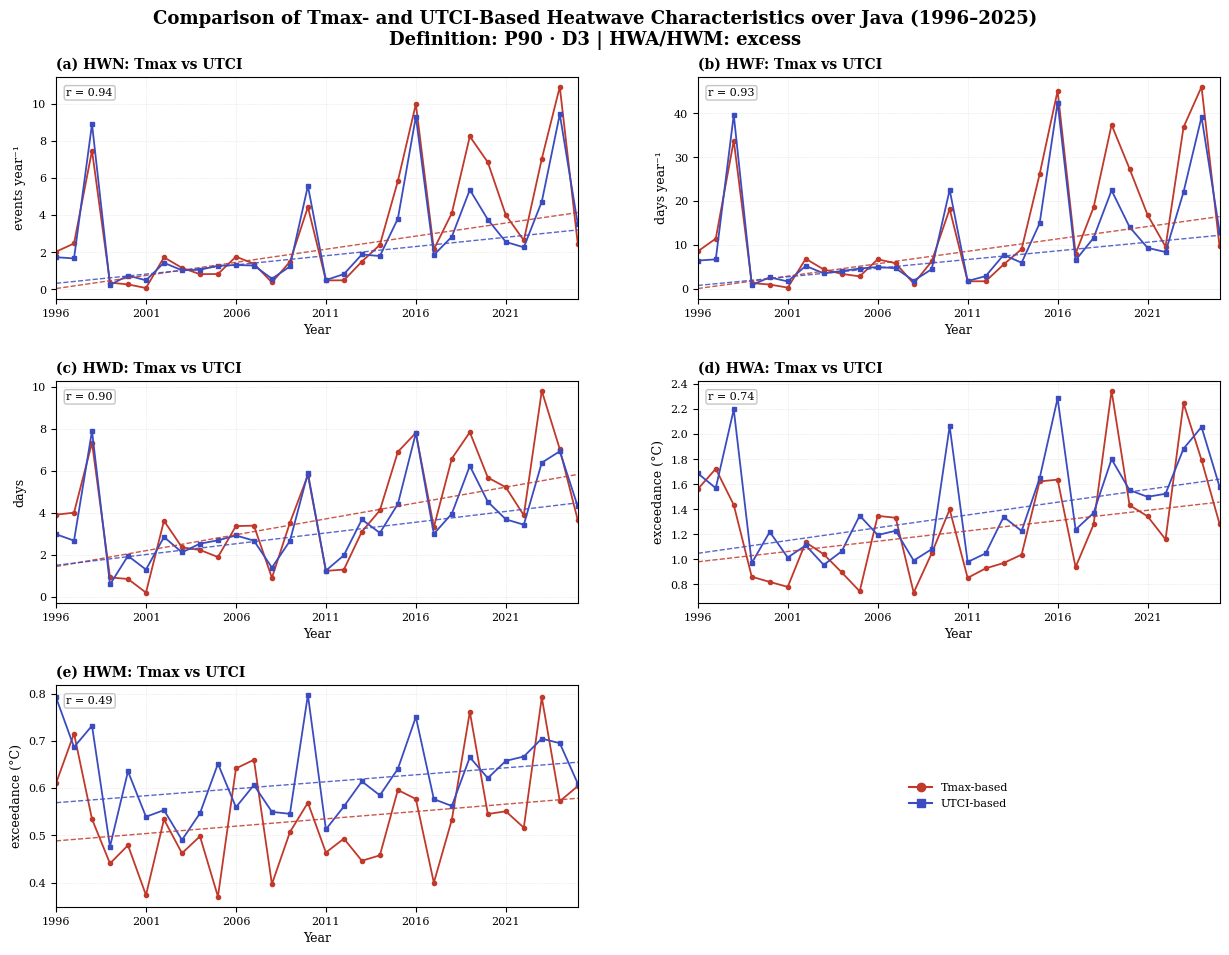

Disimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_JAWA_Comparison_V4_SMOOTH\plots\FIG01_Annual_TMAX_vs_UTCI_JAWA_P90_D3_excess.png
metric basis  sen_slope_per_decade  kendall_p
   HWN  Tmax              1.412045   0.001150
   HWN  UTCI              0.991463   0.001150
   HWF  Tmax              5.669529   0.001966
   HWF  UTCI              3.951003   0.001966
   HWD  Tmax              1.512018   0.006679
   HWD  UTCI              1.025773   0.000870
   HWA  Tmax              0.164520   0.074217
   HWA  UTCI              0.204163   0.017581
   HWM  Tmax              0.031087   0.188428
   HWM  UTCI              0.029512   0.101015


In [2]:
# ============================================================
# FIGURE 1 — ANNUAL TMAX vs UTCI, 5 PANEL + LEGEND
# ============================================================
tmax_df = pd.read_csv(TMAX_ANNUAL_CSV)
utci_df = pd.read_csv(UTCI_ANNUAL_CSV)
required_cols = {'scenario','year','HWN','HWF','HWD','HWA_abs','HWM_abs','HWA_excess','HWM_excess'}
for basis, df in [('Tmax', tmax_df), ('UTCI', utci_df)]:
    absent = sorted(required_cols - set(df.columns))
    if absent:
        raise KeyError(f'Kolom {basis} hilang: {absent}. Periksa versi workflow asal.')
    if df[['scenario','year']].duplicated().any():
        raise ValueError(f'{basis}: baris scenario-year duplikat.')
T = tmax_df.loc[tmax_df.scenario.astype(str).eq(MAIN_SCENARIO)].sort_values('year')
U = utci_df.loc[utci_df.scenario.astype(str).eq(MAIN_SCENARIO)].sort_values('year')
if not np.array_equal(T.year.to_numpy(), YEARS) or not np.array_equal(U.year.to_numpy(), YEARS):
    raise ValueError('CSV tidak memuat tepat 30 tahun (1996–2025) pada skenario utama.')

hwa_key, hwm_key = 'HWA_'+INTENSITY_MODE, 'HWM_'+INTENSITY_MODE
intensity_unit = 'exceedance (°C)' if INTENSITY_MODE=='excess' else 'index value (°C)'
specs = [('HWN','HWN','events year⁻¹'), ('HWF','HWF','days year⁻¹'),
         ('HWD','HWD','days'), (hwa_key,'HWA',intensity_unit),
         (hwm_key,'HWM',intensity_unit)]
fig = plt.figure(figsize=(13,10))
gs=fig.add_gridspec(3,2,left=.085,right=.98,bottom=.07,top=.90,hspace=.37,wspace=.23)
rows=[]
for i,(col,code,ylabel) in enumerate(specs):
    ax=fig.add_subplot(gs[i//2,i%2])
    tv=T[col].to_numpy(float); uv=U[col].to_numpy(float)
    ax.plot(YEARS,tv,'o-',color='#c0392b',ms=3,lw=1.3,label='Tmax-based')
    ax.plot(YEARS,uv,'s-',color='#3b4cc0',ms=2.8,lw=1.3,label='UTCI-based')
    for data,base,color in ((tv,'Tmax','#c0392b'),(uv,'UTCI','#3b4cc0')):
        good=np.isfinite(data)
        if good.sum()>=10:
            fit=theilslopes(data[good],YEARS[good],alpha=.95)
            ax.plot(YEARS,fit.intercept+fit.slope*YEARS,ls='--',lw=1,color=color,alpha=.85)
            pval=kendalltau(YEARS[good],data[good]).pvalue
            rows.append({'metric':code,'basis':base,'sen_slope_per_decade':fit.slope*10,
                         'kendall_p':pval})
    common=np.isfinite(tv)&np.isfinite(uv)
    corr = (np.corrcoef(tv[common],uv[common])[0,1] if common.sum()>=3 and
            np.nanstd(tv[common])>0 and np.nanstd(uv[common])>0 else np.nan)
    ax.text(.02,.95,f'r = {corr:.2f}' if np.isfinite(corr) else 'r = N/A',
            transform=ax.transAxes,ha='left',va='top',fontsize=8,
            bbox={'boxstyle':'round,pad=.2','facecolor':'white','edgecolor':'0.75','alpha':.9})
    ax.set_title(f'({chr(97+i)}) {code}: Tmax vs UTCI',weight='bold',loc='left')
    ax.set_ylabel(ylabel);ax.set_xlabel('Year')
    ax.set_xlim(START_YEAR,END_YEAR);ax.set_xticks(np.arange(START_YEAR,END_YEAR+1,5))
    ax.grid(ls=':',lw=.5,alpha=.45)
leg=fig.add_subplot(gs[2,1]);leg.axis('off')
from matplotlib.lines import Line2D
leg.legend([Line2D([0],[0],color='#c0392b',marker='o'),
            Line2D([0],[0],color='#3b4cc0',marker='s')],
           ['Tmax-based','UTCI-based'],loc='center',frameon=False)
fig.suptitle('Comparison of Tmax- and UTCI-Based Heatwave Characteristics over Java '
             f'({START_YEAR}–{END_YEAR})\nDefinition: {MAIN_SCENARIO.replace("_"," · ")} | '
             f'HWA/HWM: {INTENSITY_MODE}',fontweight='bold',y=.967)
save_figure(fig,f'FIG01_Annual_TMAX_vs_UTCI_JAWA_{MAIN_SCENARIO}_{INTENSITY_MODE}.png')
annual_trend_summary=pd.DataFrame(rows)
annual_trend_summary.to_csv(TABLE_DIR / 'TABLE01_Annual_Trend_Comparison.csv',index=False)
print(annual_trend_summary.to_string(index=False))

## 2. Load cache harian Tmax dan UTCImax + QC grid

**Perbaikan khas Jawa:** nama file cache Tmax memuat fingerprint agar versi wilayah lama tidak dipakai. Notebook menemukan kelompok cache `.json/.dat/.npy` dan pasangan threshold + metric NPZ ber-fingerprint yang sama. Koordinat cache direkonstruksi dari **file mentah Tmax** dengan urutan longitude/latitude ascending persis seperti workflow Tmax Jawa. Tidak ada interpolasi untuk perbandingan statistik, dan kedua data harus mempunyai tanggal 1996–2025 yang identik.

In [3]:
# ============================================================
# 2A. TEMUKAN CACHE TMAX JAWA SESUAI FINGERPRINT
# ============================================================
def select_tmax_cache(folder):
    metas=sorted(folder.glob('daily_metadata_jawa_1996_2025_*.json'),
                 key=lambda p:p.stat().st_mtime,reverse=True)
    candidates=[]
    for path in metas:
        try:
            meta=json.loads(path.read_text(encoding='utf-8'))
            tag=path.stem.removeprefix('daily_metadata_')
            fingerprint=tag.split('_')[-1]
            dat=folder/f'daily_tmax_{tag}.dat'
            dt=folder/f'daily_dates_{tag}.npy'
            thr=folder/f'calendar_thresholds_P90_P95_W15_{tag}.npz'
            metric=folder/f'metrics_{MAIN_SCENARIO}_W15_{tag}.npz'
            if not all(p.exists() for p in (dat,dt,thr,metric)):
                continue
            shape=tuple(meta.get('shape',()))
            if (meta.get('region')!='Jawa' or meta.get('dtype')!='float32' or
                meta.get('period')!=[START_YEAR,END_YEAR] or
                meta.get('fingerprint')!=fingerprint or len(shape)!=3 or
                dat.stat().st_size!=int(np.prod(shape))*np.dtype('float32').itemsize):
                continue
            ds=np.load(dt,allow_pickle=False).astype('datetime64[D]')
            if len(ds)!=shape[0] or not np.array_equal(
                ds,pd.date_range(f'{START_YEAR}-01-01',f'{END_YEAR}-12-31',freq='D').to_numpy(dtype='datetime64[D]')):
                continue
            candidates.append((path,meta,dat,dt,thr,metric,shape))
        except (OSError,ValueError,KeyError,TypeError) as exc:
            print('Lewati metadata cache:',path.name,exc)
    if not candidates:
        raise FileNotFoundError(
            'Cache Tmax JAWA lengkap tidak ditemukan di '+str(folder)+'\n'
            'Diperlukan daily_metadata_...json, daily_tmax_...dat, daily_dates_...npy, '
            'calendar_thresholds_...npz dan metrics_'+MAIN_SCENARIO+'_...npz dengan fingerprint yang sama. '
            'Jalankan notebook Tmax Jawa terlebih dahulu atau perbaiki TMAX_ROOT.')
    if len(candidates)>1:
        print('Catatan: lebih dari satu cache Jawa valid; memakai yang TERBARU:',candidates[0][0].name)
    return candidates[0]

(meta_path,tmax_meta,TMAX_DAILY_DAT,TMAX_DAILY_DATES,TMAX_THRESHOLD_NPZ,
 TMAX_METRIC_NPZ,tmax_shape)=select_tmax_cache(TMAX_CACHE)
tmax_dates=np.load(TMAX_DAILY_DATES,allow_pickle=False).astype('datetime64[D]')
tmax_values=np.memmap(TMAX_DAILY_DAT,dtype='float32',mode='r',shape=tmax_shape)

raw_files=sorted(TMAX_RAW_DIR.glob('*.nc'))
if not raw_files:
    raise FileNotFoundError('Koordinat cache Tmax perlu satu contoh NetCDF mentah di '+str(TMAX_RAW_DIR)+
                            '. Ubah TMAX_RAW_DIR sesuai input notebook Tmax Jawa.')
with Dataset(raw_files[0],'r') as raw:
    lower={k.lower():k for k in raw.variables}
    def coord(names):
        for name in names:
            if name.lower() in lower:
                return np.asarray(raw.variables[lower[name.lower()]][:],dtype=float)
        raise KeyError('Koordinat '+str(names)+' tak ditemukan pada '+str(raw_files[0]))
    tmax_lat=coord(('latitude','lat'))
    tmax_lon=coord(('longitude','lon'))
if tmax_lat.ndim!=1 or tmax_lon.ndim!=1:
    raise ValueError('Tmax harus punya koordinat latitude/longitude 1-D.')
if np.nanmax(tmax_lon)>180:
    tmax_lon=((tmax_lon+180)%360)-180
tmax_lat=np.sort(tmax_lat);tmax_lon=np.sort(tmax_lon)
if (len(tmax_lat),len(tmax_lon))!=tmax_shape[1:]:
    raise ValueError('Shape koordinat dari raw Tmax tidak cocok cache memmap. Periksa TMAX_RAW_DIR.')
if np.any(np.diff(tmax_lat)<=0) or np.any(np.diff(tmax_lon)<=0):
    raise ValueError('Koordinat raw Tmax duplikat.')

print('Tmax cache     :',TMAX_DAILY_DAT.name)
print('Tmax threshold :',TMAX_THRESHOLD_NPZ.name)
print('Tmax metrics   :',TMAX_METRIC_NPZ.name)
print('Tmax shape     :',tmax_values.shape)
print('Tmax coords    :',tmax_lat[[0,-1]],tmax_lon[[0,-1]])

Tmax cache     : daily_tmax_jawa_1996_2025_12a9a5da2da0.dat
Tmax threshold : calendar_thresholds_P90_P95_W15_jawa_1996_2025_12a9a5da2da0.npz
Tmax metrics   : metrics_P90_D3_W15_jawa_1996_2025_12a9a5da2da0.npz
Tmax shape     : (10958, 15, 45)
Tmax coords    : [-9.  -5.5] [104. 115.]


In [4]:
# ============================================================
# 2B. LOAD UTCI DAILY, MASK, COORDINATE ALIGNMENT
# ============================================================
with xr.open_dataset(UTCI_DAILY_FILE,decode_timedelta=False) as ds:
    if 'utci_max' not in ds:
        raise KeyError(f'utci_max tidak ditemukan pada {UTCI_DAILY_FILE}')
    utci_da=ds['utci_max'].transpose('time','latitude','longitude')
    utci_values=np.asarray(utci_da.values,dtype=np.float32)
    utci_dates=pd.DatetimeIndex(utci_da.time.values).to_numpy(dtype='datetime64[D]')
    utci_lat=np.asarray(utci_da.latitude.values,dtype=float)
    utci_lon=np.asarray(utci_da.longitude.values,dtype=float)
    utci_units=str(utci_da.attrs.get('units','')).lower().strip()
with xr.open_dataset(UTCI_MASK_FILE,decode_timedelta=False) as ds:
    mask_da=ds['java_mask'].transpose('latitude','longitude')
    utci_land=np.asarray(mask_da.values,dtype=bool)
    if not np.allclose(mask_da.latitude.values,utci_lat,rtol=0,atol=GRID_TOL):
        raise ValueError('Latitude mask UTCI tidak cocok dengan daily UTCI.')
    if not np.allclose(mask_da.longitude.values,utci_lon,rtol=0,atol=GRID_TOL):
        raise ValueError('Longitude mask UTCI tidak cocok dengan daily UTCI.')
if utci_units not in ('degc','c','celsius','degree_celsius','degrees_celsius','°c'):
    raise ValueError(f'UTCI harus berunit Celsius, metadata terdeteksi: {utci_units!r}')
if not np.array_equal(tmax_dates,utci_dates):
    raise ValueError('Tanggal Tmax dan UTCI Jawa tidak identik. Cek periode 1996–2025.')

def coord_indices(source,target,name):
    source=np.asarray(source,float);target=np.asarray(target,float)
    idx=[];missing=[]
    for value in target:
        hits=np.flatnonzero(np.isclose(source,value,rtol=0,atol=GRID_TOL))
        if len(hits)!=1:missing.append((float(value),len(hits)))
        else:idx.append(int(hits[0]))
    if missing:
        raise ValueError(f'Grid {name} berbeda, tidak ada pencocokan grid native satu-ke-satu. '
                         f'Contoh: {missing[:5]}.\nTmax: [{source.min():.4f}, {source.max():.4f}] ({len(source)}); '
                         f'UTCI: [{target.min():.4f}, {target.max():.4f}] ({len(target)}). '
                         'Perbandingan selisih butuh grid setara; jangan ubah resolusi secara diam-diam.')
    return np.asarray(idx,dtype=int)
lat_idx=coord_indices(tmax_lat,utci_lat,'latitude')
lon_idx=coord_indices(tmax_lon,utci_lon,'longitude')
cmp_lat=utci_lat.copy();cmp_lon=utci_lon.copy()
# Memmap Tmax tetap pada disk; subset dibaca sekali dengan shape sesuai UTCI.
tmax_cmp=np.take(np.take(tmax_values,lat_idx,axis=1),lon_idx,axis=2)
utci_cmp=utci_values.copy()
utci_cmp[:,~utci_land]=np.nan
if tmax_cmp.shape!=utci_cmp.shape:
    raise ValueError('Shape Tmax/UTCI setelah alignment tidak sama.')
tmax_valid_grid=np.isfinite(tmax_cmp).any(axis=0)
utci_valid_grid=utci_land & np.isfinite(utci_cmp).any(axis=0)
common_grid=tmax_valid_grid & utci_valid_grid
if not common_grid.any():
    raise ValueError('Tidak ada common valid grid Jawa. Cek mask dan path input.')
print('Alignment         : Exact coordinate matching (tanpa regridding)')
print('Daily shape       :',tmax_cmp.shape)
print('Valid Tmax cells  :',int(tmax_valid_grid.sum()))
print('Valid UTCI cells  :',int(utci_valid_grid.sum()))
print('Common grid cells :',int(common_grid.sum()))
if common_grid.sum()<0.75*min(tmax_valid_grid.sum(),utci_valid_grid.sum()):
    warnings.warn('Overlap mask kurang dari 75%. Periksa kesesuaian mask sumber.')

Alignment         : Exact coordinate matching (tanpa regridding)
Daily shape       : (10958, 12, 36)
Valid Tmax cells  : 176
Valid UTCI cells  : 176
Common grid cells : 176


## 3. Threshold kalender-harian dan event masks (reset setiap tahun)

Threshold `P90/P95` bersifat **calendar-day percentile** jendela 15 hari, dan 29 Februari memakai rerata threshold 28 Februari dan 1 Maret. Event `D3/D4/D5` didefinisikan sebagai sekurang-kurangnya D hari berturut-turut melampaui threshold **dalam satu tahun kalender**; ini menjaga kesesuaian dengan cache HWF tahunan pada kedua workflow Jawa.

In [5]:
# ============================================================
# 3. READ THRESHOLD + EVENT DETECTION (YEAR-BY-YEAR)
# ============================================================
m=re.fullmatch(r'P(\d+)_D(\d+)',MAIN_SCENARIO)
P,D=int(m.group(1)),int(m.group(2))
with np.load(TMAX_THRESHOLD_NPZ,allow_pickle=False) as z:
    tmax_thr_raw=np.asarray(z[f'P{P}'],dtype=np.float32)
with xr.open_dataset(UTCI_THRESHOLD_FILE,decode_timedelta=False) as ds:
    utci_thr_cal=np.asarray(ds[f'P{P}'].transpose('dayofyear','latitude','longitude').values,dtype=np.float32)
    if not np.allclose(ds.latitude.values,cmp_lat,atol=GRID_TOL,rtol=0) or not np.allclose(ds.longitude.values,cmp_lon,atol=GRID_TOL,rtol=0):
        raise ValueError('Grid UTCI threshold berbeda dengan daily UTCI.')
tmax_thr_cal=np.take(np.take(tmax_thr_raw,lat_idx,axis=1),lon_idx,axis=2)
if tmax_thr_cal.shape!=utci_thr_cal.shape or tmax_thr_cal.shape[0]!=365:
    raise ValueError('Bentuk threshold P90/P95 tidak cocok sesudah alignment.')

all_dates=pd.DatetimeIndex(tmax_dates.astype('datetime64[ns]'))
cal_index=np.array([((d.dayofyear-1)-(1 if d.is_leap_year and d.month>2 else 0))
                    if not (d.month==2 and d.day==29) else -1 for d in all_dates],dtype=np.int16)
def threshold_days(calendar,ids):
    subset=cal_index[ids]
    d=calendar[np.maximum(subset,0)].copy()
    leap=subset==-1
    if leap.any():d[leap]=.5*(calendar[58]+calendar[59])
    return d

def mark_events(exceed,minimum):
    """Tandai seluruh run >= minimum hari; vectorized antarsel grid."""
    exc=np.asarray(exceed,bool)
    n=exc.shape[0]
    count_f=np.zeros_like(exc,dtype=np.uint16)
    count=np.zeros(exc.shape[1:],np.uint16)
    for t in range(n):
        count=np.where(exc[t],count+1,0)
        count_f[t]=count
    result=np.zeros_like(exc,dtype=bool)
    count[:]=0
    for t in range(n-1,-1,-1):
        count=np.where(exc[t],count+1,0)
        result[t]=exc[t]&((count_f[t]+count-1)>=minimum)
    return result

T_hw=np.zeros(tmax_cmp.shape,dtype=bool)
U_hw=np.zeros(utci_cmp.shape,dtype=bool)
for year in YEARS:
    ids=np.flatnonzero(all_dates.year==year)
    t_thr=threshold_days(tmax_thr_cal,ids)
    u_thr=threshold_days(utci_thr_cal,ids)
    t_exc=np.isfinite(tmax_cmp[ids])&np.isfinite(t_thr)&(tmax_cmp[ids]>t_thr)
    u_exc=np.isfinite(utci_cmp[ids])&np.isfinite(u_thr)&(utci_cmp[ids]>u_thr)
    T_hw[ids]=mark_events(t_exc,D)
    U_hw[ids]=mark_events(u_exc,D)
print('Heatwave detection completed: reset at each calendar-year boundary.')
print('Tmax HW grid-days:',int(T_hw.sum()))
print('UTCI HW grid-days:',int(U_hw.sum()))

# QC perbandingan HWF pada cache asal: dilakukan pada grid dan tahun yang sama.
with np.load(TMAX_METRIC_NPZ,allow_pickle=False) as z:
    cache_hwf=np.asarray(z['HWF'],dtype=np.float32)
    cache_years=np.asarray(z['years'])
if not np.array_equal(cache_years,YEARS):
    raise ValueError('Tahun pada cache metrik Tmax tidak cocok 1996–2025.')
with xr.open_dataset(UTCI_METRICS_FILE,decode_timedelta=False) as ds:
    cached_u_hwf=np.asarray(ds['HWF'].sel(percentile=P,min_duration=D)
                            .transpose('year','latitude','longitude').values,dtype=np.float32)
    if not np.array_equal(np.asarray(ds.year.values,dtype=int),YEARS):
        raise ValueError('Tahun metrik UTCI tidak cocok dengan 1996–2025.')
# Periksa 12 titik grid valid dan 3 tahun tersebar (agar ringan).
indices=np.argwhere(common_grid)
checks=indices[np.linspace(0,len(indices)-1,min(12,len(indices)),dtype=int)]
for yy in (1996,2010,2025):
    ti=yy-START_YEAR; ids=all_dates.year==yy
    for r,c in checks:
        t_idx=(lat_idx[r],lon_idx[c])
        n_t=int(T_hw[ids,r,c].sum());n_u=int(U_hw[ids,r,c].sum())
        ct=cache_hwf[ti,t_idx[0],t_idx[1]]
        cu=cached_u_hwf[ti,r,c]
        if np.isfinite(ct) and not np.isclose(n_t,ct,atol=0.1):
            raise ValueError(f'QC HWF Tmax mismatch {yy} grid {r,c}: harian={n_t}, cache={ct}')
        if np.isfinite(cu) and not np.isclose(n_u,cu,atol=0.1):
            raise ValueError(f'QC HWF UTCI mismatch {yy} grid {r,c}: harian={n_u}, cache={cu}')
print('QC HWF harian vs cache tahunan: LULUS (sampel grid/tahun).')

Heatwave detection completed: reset at each calendar-year boundary.
Tmax HW grid-days: 72355
UTCI HW grid-days: 59083
QC HWF harian vs cache tahunan: LULUS (sampel grid/tahun).


## 4. Pilih otomatis case study panas ekstrem

Default **overlap** mencari hari dengan aktivitas Tmax dan UTCI yang sama-sama kuat pada wilayah yang sama. Alternatif: `contrast`, `tmax`, atau `utci`. Persentase luas menggunakan bobot `cos(latitude)`. Kalau tidak ada kejadian terdeteksi, notebook meminta penggantian skenario atau pemeriksaan threshold (tidak menampilkan kasus palsu).

In [6]:
# ============================================================
# 4. AREA-WEIGHTED EVENT FRACTION + SELECT CASE STUDY
# ============================================================
area_weights=np.broadcast_to(np.cos(np.deg2rad(cmp_lat))[:,None],common_grid.shape).copy()
def weighted_fraction_ts(bool3d,static_mask):
    w=np.where(static_mask,area_weights,0.)
    den=w.sum()
    if den<=0:raise ValueError('Luas valid untuk perhitungan area adalah nol.')
    return 100*np.einsum('tij,ij->t',bool3d.astype(np.float32),w,optimize=True)/den
T_area_all=weighted_fraction_ts(T_hw,tmax_valid_grid)
U_area_all=weighted_fraction_ts(U_hw,utci_valid_grid)
common_active=T_hw&U_hw&common_grid[None,:,:]
B_area_all=weighted_fraction_ts(common_active,common_grid)
if AUTO_CASE:
    if CASE_SELECTION=='overlap':
        score=2*B_area_all+np.minimum(T_area_all,U_area_all)
    elif CASE_SELECTION=='contrast':score=np.abs(T_area_all-U_area_all)
    elif CASE_SELECTION=='tmax':score=T_area_all
    elif CASE_SELECTION=='utci':score=U_area_all
    else:raise ValueError('CASE_SELECTION: overlap/contrast/tmax/utci')
    if not np.isfinite(score).any() or np.nanmax(score)<=0:
        raise ValueError('Tidak ada hari heatwave untuk pemilihan otomatis. Periksa mask, threshold atau skenario.')
    peak_idx=int(np.nanargmax(score))
else:
    desired=np.datetime64(CASE_CENTER,'D')
    matched=np.flatnonzero(tmax_dates==desired)
    if not len(matched):raise ValueError('CASE_CENTER tidak ada dalam data harian.')
    peak_idx=int(matched[0])
center_date=pd.Timestamp(tmax_dates[peak_idx])
start_i=max(0,peak_idx-CASE_HALF_WINDOW_DAYS)
end_i=min(len(tmax_dates),peak_idx+CASE_HALF_WINDOW_DAYS+1)
case_slice=slice(start_i,end_i)
case_indices=np.arange(start_i,end_i)
case_dates=pd.DatetimeIndex(tmax_dates[case_slice])
print('Case center :',center_date.strftime('%d %b %Y'))
print('Window      :',case_dates.min(),'-',case_dates.max())
print('Tmax peak % :',round(float(T_area_all[peak_idx]),2))
print('UTCI peak % :',round(float(U_area_all[peak_idx]),2))
print('Overlap %   :',round(float(B_area_all[peak_idx]),2))

Case center : 28 Feb 2010
Window      : 2010-02-18 00:00:00 - 2010-03-10 00:00:00
Tmax peak % : 65.36
UTCI peak % : 48.89
Overlap %   : 44.91


## 5. Figure 2 — Studi kasus harian (5 panel)

(a) luas area terpengaruh; (b) Tmax terhadap ambang P90/P95; (c) UTCImax terhadap ambang masing-masing; (d) rata-rata anomali relatif ambang; (e) area yang dideteksi keduanya / Tmax saja / UTCI saja. Area agreement hanya dihitung pada **common support**, sehingga panel (e) tidak memakai sel yang data pasangannya kosong.

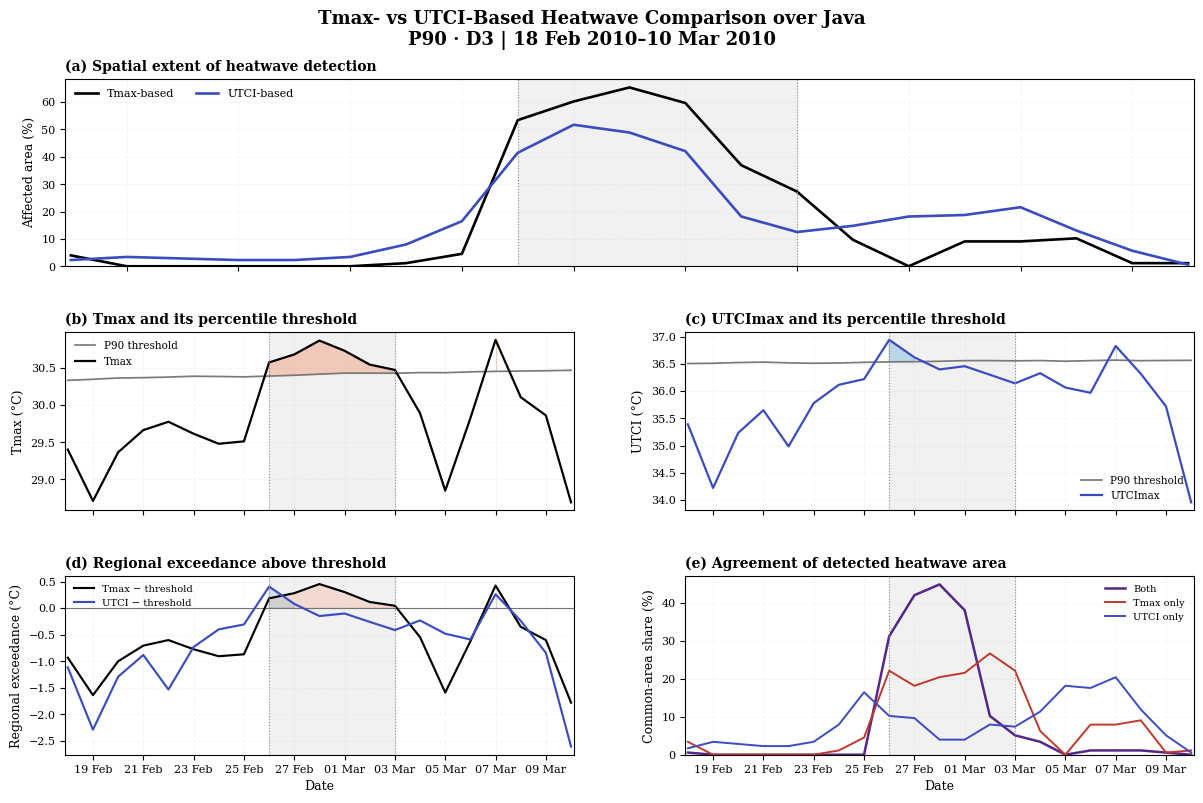

Disimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_JAWA_Comparison_V4_SMOOTH\plots\FIG02_CaseStudy_TMAX_vs_UTCI_JAWA_P90_D3_20100228.png
      date  tmax_affected_area_pct  utci_affected_area_pct  both_common_area_pct  tmax_only_common_area_pct  utci_only_common_area_pct  tmax_mean_C  tmax_threshold_C  utci_mean_C  utci_threshold_C  tmax_excess_C  utci_excess_C
2010-02-18                3.971048                2.269156               0.56764                   3.403408                   1.701517    29.400985         30.333333    35.388974         36.505359      -0.932348      -1.116386
2010-02-19                0.000000                3.406073               0.00000                   0.000000                   3.406073    28.708908         30.347801    34.222089         36.510510      -1.638894      -2.288421
2010-02-20                0.000000                2.839835               0.00000                   0.000000                   2.839835    29.364029         30.365127 

In [7]:
# ============================================================
# FIGURE 2 — PAPER-STYLE CASE STUDY (5 PANELS)
# ============================================================
def weighted_ts(arr,static_mask):
    w=np.where(static_mask,area_weights,0.)
    a=np.asarray(arr,dtype=float)
    mask=np.isfinite(a)
    nums=np.einsum('tij,ij->t',np.where(mask,a,0.),w,optimize=True)
    dens=np.einsum('tij,ij->t',mask.astype(float),w,optimize=True)
    return np.divide(nums,dens,out=np.full(len(a),np.nan),where=dens>0)

def case_calendar_values(cal):
    return threshold_days(cal,case_indices)
T_mean=weighted_ts(tmax_cmp[case_slice],tmax_valid_grid)
U_mean=weighted_ts(utci_cmp[case_slice],utci_valid_grid)
T_thr_mean=weighted_ts(case_calendar_values(tmax_thr_cal),tmax_valid_grid)
U_thr_mean=weighted_ts(case_calendar_values(utci_thr_cal),utci_valid_grid)
T_excess=T_mean-T_thr_mean
U_excess=U_mean-U_thr_mean
T_area=T_area_all[case_slice];U_area=U_area_all[case_slice]
Both_pct=weighted_fraction_ts(T_hw[case_slice]&U_hw[case_slice]&common_grid[None],common_grid)
T_only_pct=weighted_fraction_ts(T_hw[case_slice]&~U_hw[case_slice]&common_grid[None],common_grid)
U_only_pct=weighted_fraction_ts(U_hw[case_slice]&~T_hw[case_slice]&common_grid[None],common_grid)
activity=np.maximum(T_area,U_area)
local_peak=int(np.nanargmax(activity))
cut=CORE_ACTIVITY_FRACTION*float(activity[local_peak])
left=right=local_peak
while left>0 and activity[left-1]>=cut:left-=1
while right<len(activity)-1 and activity[right+1]>=cut:right+=1
core_start=case_dates[left];core_end=case_dates[right]

fig=plt.figure(figsize=(12.4,8.4))
gs=fig.add_gridspec(3,2,height_ratios=[1.05,1,1],hspace=.36,wspace=.22,
                    left=.075,right=.985,bottom=.085,top=.89)
ax_a=fig.add_subplot(gs[0,:]);ax_b=fig.add_subplot(gs[1,0],sharex=ax_a)
ax_c=fig.add_subplot(gs[1,1],sharex=ax_a);ax_d=fig.add_subplot(gs[2,0],sharex=ax_a)
ax_e=fig.add_subplot(gs[2,1],sharex=ax_a)
axes=[ax_a,ax_b,ax_c,ax_d,ax_e]
def mark_core(ax):
    ax.axvspan(core_start,core_end,color='.93',alpha=.75,zorder=0)
    ax.axvline(core_start,color='.55',ls=':',lw=.8)
    ax.axvline(core_end,color='.55',ls=':',lw=.8)
ax_a.plot(case_dates,T_area,color='black',lw=1.9,label='Tmax-based')
ax_a.plot(case_dates,U_area,color='#3b4cc0',lw=1.9,label='UTCI-based')
ax_a.set_ylabel('Affected area (%)');ax_a.set_ylim(bottom=0)
ax_a.set_title('(a) Spatial extent of heatwave detection',loc='left',weight='bold')
ax_a.legend(frameon=False,ncol=2,loc='upper left')
ax_b.plot(case_dates,T_thr_mean,color='.48',lw=1.25,label=f'P{P} threshold')
ax_b.plot(case_dates,T_mean,color='black',lw=1.6,label='Tmax')
ax_b.fill_between(case_dates,T_thr_mean,T_mean,where=(T_mean>=T_thr_mean),color='#ef8a62',alpha=.38)
ax_b.set_ylabel('Tmax (°C)');ax_b.set_title('(b) Tmax and its percentile threshold',loc='left',weight='bold')
ax_b.legend(frameon=False,fontsize=7.5)
ax_c.plot(case_dates,U_thr_mean,color='.48',lw=1.25,label=f'P{P} threshold')
ax_c.plot(case_dates,U_mean,color='#3b4cc0',lw=1.6,label='UTCImax')
ax_c.fill_between(case_dates,U_thr_mean,U_mean,where=(U_mean>=U_thr_mean),color='#67a9cf',alpha=.38)
ax_c.set_ylabel('UTCI (°C)');ax_c.set_title('(c) UTCImax and its percentile threshold',loc='left',weight='bold')
ax_c.legend(frameon=False,fontsize=7.5)
ax_d.axhline(0,color='.45',lw=.8)
ax_d.plot(case_dates,T_excess,color='black',lw=1.55,label='Tmax − threshold')
ax_d.plot(case_dates,U_excess,color='#3b4cc0',lw=1.55,label='UTCI − threshold')
ax_d.fill_between(case_dates,0,T_excess,where=(T_excess>=0),color='#ef8a62',alpha=.22)
ax_d.fill_between(case_dates,0,U_excess,where=(U_excess>=0),color='#67a9cf',alpha=.22)
ax_d.set_ylabel('Regional exceedance (°C)')
ax_d.set_title('(d) Regional exceedance above threshold',loc='left',weight='bold')
ax_d.legend(frameon=False,fontsize=7.2)
ax_e.plot(case_dates,Both_pct,color='#542788',lw=1.8,label='Both')
ax_e.plot(case_dates,T_only_pct,color='#c0392b',lw=1.4,label='Tmax only')
ax_e.plot(case_dates,U_only_pct,color='#3b4cc0',lw=1.4,label='UTCI only')
ax_e.set_ylabel('Common-area share (%)');ax_e.set_ylim(bottom=0)
ax_e.set_title('(e) Agreement of detected heatwave area',loc='left',weight='bold')
ax_e.legend(frameon=False,fontsize=7.1)
for ax in axes:
    mark_core(ax);ax.grid(ls=':',lw=.45,alpha=.35)
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax.margins(x=.005)
for ax in (ax_a,ax_b,ax_c):plt.setp(ax.get_xticklabels(),visible=False)
ax_d.set_xlabel('Date');ax_e.set_xlabel('Date')
fig.suptitle('Tmax- vs UTCI-Based Heatwave Comparison over Java\n'
             f'{MAIN_SCENARIO.replace("_"," · ")} | '
             f'{case_dates[0]:%d %b %Y}–{case_dates[-1]:%d %b %Y}',weight='bold',y=.972)
save_figure(fig,f'FIG02_CaseStudy_TMAX_vs_UTCI_JAWA_{MAIN_SCENARIO}_{center_date:%Y%m%d}.png')
case_summary=pd.DataFrame({'date':case_dates,'tmax_affected_area_pct':T_area,
'utci_affected_area_pct':U_area,'both_common_area_pct':Both_pct,
'tmax_only_common_area_pct':T_only_pct,'utci_only_common_area_pct':U_only_pct,
'tmax_mean_C':T_mean,'tmax_threshold_C':T_thr_mean,'utci_mean_C':U_mean,
'utci_threshold_C':U_thr_mean,'tmax_excess_C':T_excess,'utci_excess_C':U_excess})
case_summary.to_csv(TABLE_DIR/'TABLE02_CaseStudy_Daily_Comparison.csv',index=False)
print(case_summary.head().to_string(index=False))

## 6. Figure 3 — Peta HWF Jawa, tiga panel, *smooth*

Panel (a) **Tmax HWF**, (b) **UTCI HWF** menggunakan skala warna identik. Panel (c) **UTCI − Tmax**, hanya pada *common valid grid*, dengan colorbar simetris berpusat di 0. Peta *smooth* memakai interpolasi linear untuk penampilan saja, diklip oleh jejak grid valid dan geometri enam provinsi Jawa bila tersedia. **Hasil statistik dan angka perbedaan tetap pada grid native.**

Map QC valid points Tmax, UTCI, common: 176 176 176


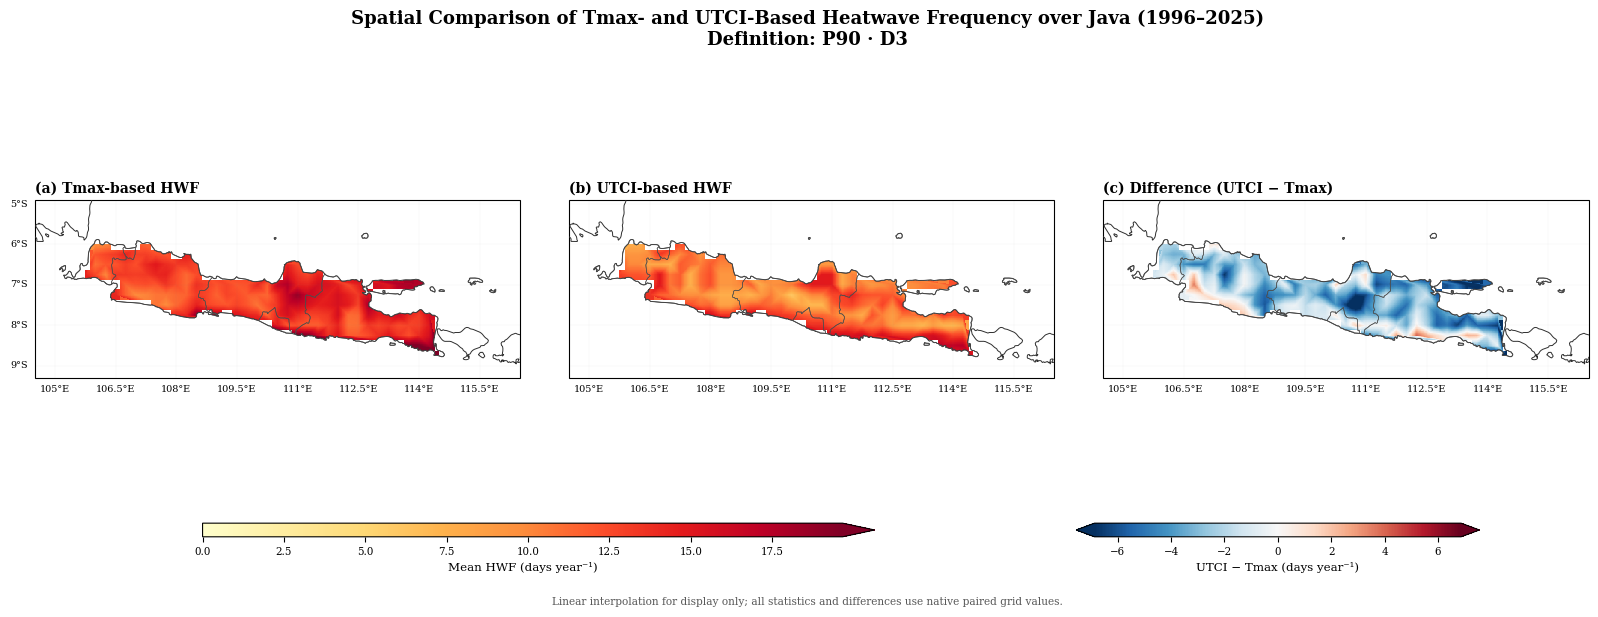

Disimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_vs_UTCI_JAWA_Comparison_V4_SMOOTH\plots\FIG03_Spatial_HWF_JAWA_TMAX_vs_UTCI_P90_D3_SMOOTH.png


In [8]:
# ============================================================
# FIGURE 3 — SPATIAL HWF TMAX vs UTCI, SMOOTH JAWA
# ============================================================
with np.load(TMAX_METRIC_NPZ,allow_pickle=False) as z:
    if 'HWF' not in z:raise KeyError('HWF tidak ada pada cache Tmax.')
    t_metric=np.asarray(z['HWF'],dtype=float)
if t_metric.shape[0]!=len(YEARS) or t_metric.shape[1:]!=tmax_shape[1:]:
    raise ValueError('Shape spasial cache HWF Tmax tidak cocok dengan cache daily Tmax.')
Tmap_raw=np.nanmean(np.take(np.take(t_metric,lat_idx,axis=1),lon_idx,axis=2),axis=0)
with xr.open_dataset(UTCI_METRICS_FILE,decode_timedelta=False) as ds:
    metric=ds['HWF'].sel(percentile=P,min_duration=D)
    metric=metric.transpose('year','latitude','longitude')
    if not np.allclose(metric.latitude,cmp_lat,rtol=0,atol=GRID_TOL):
        raise ValueError('Latitude UTCI metrics berbeda dengan grid pembanding.')
    if not np.allclose(metric.longitude,cmp_lon,rtol=0,atol=GRID_TOL):
        raise ValueError('Longitude UTCI metrics berbeda dengan grid pembanding.')
    Umap_raw=np.nanmean(np.asarray(metric.values,dtype=float),axis=0)
Tmap=np.where(tmax_valid_grid,Tmap_raw,np.nan)
Umap=np.where(utci_valid_grid,Umap_raw,np.nan)
Dmap=np.where(common_grid & np.isfinite(Tmap)&np.isfinite(Umap),Umap-Tmap,np.nan)
print('Map QC valid points Tmax, UTCI, common:',*(np.isfinite(z).sum() for z in (Tmap,Umap,Dmap)))

bothvals=np.concatenate([z[np.isfinite(z)] for z in (Tmap,Umap)])
if not len(bothvals):raise ValueError('Tidak ada HWF finite pada peta Jawa.')
vmax=float(np.percentile(bothvals,99))
if not np.isfinite(vmax) or vmax<=0:vmax=1.
dvals=np.abs(Dmap[np.isfinite(Dmap)])
dmax=float(np.percentile(dvals,98)) if len(dvals) else 1.
if not np.isfinite(dmax) or dmax<=0:dmax=1.

province_targets={
'Banten':['banten'],
'DKI Jakarta':['jakarta raya','dki jakarta','jakarta','djakarta'],
'Jawa Barat':['west java','jawa barat'],
'Jawa Tengah':['central java','jawa tengah'],
'DI Yogyakarta':['yogyakarta','di yogyakarta','special region of yogyakarta'],
'Jawa Timur':['east java','jawa timur']}
def norm_name(t):return re.sub(r'[^a-z0-9]+',' ',str(t).lower()).strip()
java_geoms=[];found_provinces=[]
try:
    shp=Path(SHAPEFILE_ADMIN1) if SHAPEFILE_ADMIN1 else shpreader.natural_earth(
        resolution='10m',category='cultural',name='admin_1_states_provinces')
    records=list(shpreader.Reader(shp).records())
    for prov,aliases in province_targets.items():
        match=[]
        for rec in records:
            a=rec.attributes
            country=' '.join(str(a.get(k,'')) for k in ('admin','geonunit','sovereignt','iso_a3','adm0_a3')).lower()
            if 'indonesia' not in country and 'idn' not in country:continue
            names={norm_name(a.get(k,'')) for k in ('name','name_en','name_local','gn_name','name_alt')}
            if any(norm_name(alias) in names for alias in aliases):match.append(rec.geometry)
        if match:
            found_provinces.append(prov);java_geoms.extend(match)
    if len(found_provinces)!=6:
        warnings.warn('Natural Earth Jawa tidak lengkap. Provinsi ditemukan: '+', '.join(found_provinces)+
                      '. Akan memakai footprint grid native untuk clipping.')
        java_geoms=[]
except Exception as exc:
    warnings.warn(f'Batas provinsi Natural Earth gagal dibaca ({exc}); pakai native footprint.')
    java_geoms=[]
java_geom=unary_union(java_geoms) if java_geoms else None

xx1=np.linspace(MAP_EXTENT[0],MAP_EXTENT[1],DISPLAY_NX)
yy1=np.linspace(MAP_EXTENT[2],MAP_EXTENT[3],DISPLAY_NY)
xx,yy=np.meshgrid(xx1,yy1)
if java_geom is not None:
    inside=np.asarray(contains_xy(java_geom,xx,yy),bool)
else:inside=np.ones(xx.shape,bool)

def smooth_display(field):
    z=np.asarray(field,dtype=float)
    if z.shape!=(len(cmp_lat),len(cmp_lon)):
        raise ValueError('Field spasial tidak sesuai grid pembanding.')
    ilat=np.argsort(cmp_lat);ilon=np.argsort(cmp_lon)
    lat_s=cmp_lat[ilat];lon_s=cmp_lon[ilon];v=z[np.ix_(ilat,ilon)]
    good=np.isfinite(v)
    if good.sum()<3:
        warnings.warn('Titik valid terlalu sedikit untuk smoothing; memakai native.')
        return lon_s,lat_s,np.ma.masked_invalid(v)
    lon2,lat2=np.meshgrid(lon_s,lat_s)
    pts=np.column_stack([lon2[good],lat2[good]])
    try:
        fine=griddata(pts,v[good],(xx,yy),method='linear')
    except Exception as exc:
        warnings.warn(f'Interpolasi linear gagal ({exc}); memakai nearest display.')
        fine=griddata(pts,v[good],(xx,yy),method='nearest')
    missing=inside&~np.isfinite(fine)
    if missing.any():
        near=griddata(pts,v[good],(xx,yy),method='nearest')
        fine[missing]=near[missing]
    support=RegularGridInterpolator((lat_s,lon_s),good.astype('uint8'),
                                    method='nearest',bounds_error=False,fill_value=0)
    footprint=support(np.column_stack([yy.ravel(),xx.ravel()])).reshape(xx.shape).astype(bool)
    fine[~(inside&footprint)]=np.nan
    return xx1,yy1,np.ma.masked_invalid(fine)

def draw_map(ax,field,cmap,vmin,vmax):
    if SPATIAL_RENDER=='smooth':x,y,z=smooth_display(field)
    else:x,y,z=cmp_lon,cmp_lat,np.ma.masked_invalid(field)
    colormap=mpl.colormaps[cmap].copy();colormap.set_bad('white',alpha=0)
    return ax.pcolormesh(x,y,z,cmap=colormap,shading='auto',vmin=vmin,vmax=vmax,
                         rasterized=True,transform=ccrs.PlateCarree(),zorder=2)

def setup_map(ax,left=False,bottom=True):
    ax.set_extent(MAP_EXTENT,crs=ccrs.PlateCarree())
    ax.set_facecolor('white')
    try:ax.coastlines(resolution='10m',linewidth=.7,color='.18',zorder=5)
    except Exception as exc:warnings.warn(f'Coastline tidak tersedia: {exc}')
    for geom in java_geoms:
        ax.add_geometries([geom],crs=ccrs.PlateCarree(),facecolor='none',
                          edgecolor='.3',linewidth=.45,zorder=6)
    gl=ax.gridlines(draw_labels=True,linewidth=.25,linestyle=':',color='.55',alpha=.3,
                    x_inline=False,y_inline=False)
    gl.top_labels=False;gl.right_labels=False
    gl.left_labels=left;gl.bottom_labels=bottom
    gl.xlabel_style={'size':7};gl.ylabel_style={'size':7}

fig=plt.figure(figsize=(16.8,6.2))
gs=fig.add_gridspec(1,3,left=.04,right=.965,bottom=.255,top=.815,wspace=.10)
axes=[fig.add_subplot(gs[0,i],projection=ccrs.PlateCarree()) for i in range(3)]
main_cmap='YlOrRd';diff_cmap='RdBu_r'
m0=draw_map(axes[0],Tmap,main_cmap,0,vmax)
m1=draw_map(axes[1],Umap,main_cmap,0,vmax)
m2=draw_map(axes[2],Dmap,diff_cmap,-dmax,dmax)
for i,(ax,title) in enumerate(zip(axes,['(a) Tmax-based HWF','(b) UTCI-based HWF',
                                        '(c) Difference (UTCI − Tmax)'])):
    setup_map(ax,left=(i==0),bottom=True)
    ax.set_title(title,loc='left',weight='bold',pad=5)
cax1=fig.add_axes([.14,.135,.40,.022]);cb1=fig.colorbar(m1,cax=cax1,orientation='horizontal',extend='max')
cb1.set_label('Mean HWF (days year⁻¹)',fontsize=8.5);cb1.ax.tick_params(labelsize=7.4)
cax2=fig.add_axes([.66,.135,.24,.022]);cb2=fig.colorbar(m2,cax=cax2,orientation='horizontal',extend='both')
cb2.set_label('UTCI − Tmax (days year⁻¹)',fontsize=8.5);cb2.ax.tick_params(labelsize=7.4)
fig.suptitle('Spatial Comparison of Tmax- and UTCI-Based Heatwave Frequency over Java '
             f'({START_YEAR}–{END_YEAR})\nDefinition: {MAIN_SCENARIO.replace("_"," · ")}',
             weight='bold',y=.985)
fig.text(.5,.025,'Linear interpolation for display only; all statistics and differences use native paired grid values.',
         ha='center',fontsize=7.6,color='.35')
save_figure(fig,f'FIG03_Spatial_HWF_JAWA_TMAX_vs_UTCI_{MAIN_SCENARIO}_SMOOTH.png')
# Nilai native yang dapat digunakan ulang dalam analisis/pelaporan
xr.Dataset({'HWF_Tmax':(('latitude','longitude'),Tmap.astype('float32')),
            'HWF_UTCI':(('latitude','longitude'),Umap.astype('float32')),
            'HWF_UTCI_minus_Tmax':(('latitude','longitude'),Dmap.astype('float32'))},
           coords={'latitude':cmp_lat,'longitude':cmp_lon}).to_netcdf(
               TABLE_DIR/f'TABLE03_HWF_Spatial_JAWA_{MAIN_SCENARIO}_NATIVE_GRID.nc')

## 7. Output, pemeriksaan dan interpretasi

- **Figure 1** = perbandingan tren indikator tahunan untuk definisi P dan D yang sama.
- **Figure 2** = studi kasus harian, persentase area, threshold dan kesepakatan deteksi.
- **Figure 3** = peta mean HWF dengan skala bersama dan selisih `UTCI − Tmax` pada *common grid*.

**Catatan metodologi:** threshold persentil dihitung **terpisah** dari distribusi Tmax dan UTCI; D3 adalah sedikitnya 3 hari berturut-turut dalam tahun yang sama. Tidak otomatis berarti UTCI lebih/kurang berbahaya ketika nilai HWA/HWM-nya lebih besar; indikator tersebut memiliki interpretasi fisik berbeda. Selisih spasial hanya dihitung setelah QC koordinat. Saat membuat kesimpulan skripsi, gunakan nilai native hasil cache dan CSV, bukan piksel gambar hasil interpolasi.

In [9]:
# ============================================================
# 7. OUTPUT AUDIT + QC SUMMARY
# ============================================================
files_png=sorted(PLOT_DIR.glob('FIG*.png'))
scenario_png=[p for p in files_png if MAIN_SCENARIO in p.name]
files_pdf=sorted(PLOT_DIR.glob('FIG*.pdf'))
files_tbl=sorted(TABLE_DIR.iterdir())
print('Figure PNG:',len(files_png),'| PDF:',len(files_pdf),'| Tables:',len(files_tbl))
for path in files_png+files_tbl:print(' •',path.name)
qc_info={'period':f'{START_YEAR}-{END_YEAR}','scenario':MAIN_SCENARIO,
         'intensity_mode':INTENSITY_MODE,'tmax_cache':TMAX_DAILY_DAT.name,
         'utci_daily':UTCI_DAILY_FILE.name,'tmax_valid_grid':int(tmax_valid_grid.sum()),
         'utci_valid_grid':int(utci_valid_grid.sum()),'common_valid_grid':int(common_grid.sum()),
         'case_center':str(center_date.date()),'render':SPATIAL_RENDER,
         'event_reset':'per calendar year','grid_alignment':'exact coordinate subset'}
(TABLE_DIR/'RUN_QC_Summary.json').write_text(json.dumps(qc_info,indent=2,ensure_ascii=False),encoding='utf-8')
assert len(scenario_png)>=3, 'Diharapkan setidaknya 3 Figure PNG pada skenario saat ini.'
print('\nSelesai — perbandingan Tmax vs UTCImax untuk PULAU JAWA 1996–2025.')

Figure PNG: 3 | PDF: 3 | Tables: 4
 • FIG01_Annual_TMAX_vs_UTCI_JAWA_P90_D3_excess.png
 • FIG02_CaseStudy_TMAX_vs_UTCI_JAWA_P90_D3_20100228.png
 • FIG03_Spatial_HWF_JAWA_TMAX_vs_UTCI_P90_D3_SMOOTH.png
 • RUN_QC_Summary.json
 • TABLE01_Annual_Trend_Comparison.csv
 • TABLE02_CaseStudy_Daily_Comparison.csv
 • TABLE03_HWF_Spatial_JAWA_P90_D3_NATIVE_GRID.nc

Selesai — perbandingan Tmax vs UTCImax untuk PULAU JAWA 1996–2025.
